In [ ]:
# import libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score,precision_score,recall_score,classification_report,confusion_matrix,
                            f1_score)
import joblib
from pathlib import Path
from sklearn.metrics import f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier

In [2]:
# Load the cleaned Montra guest experience dataset from the CSV file
merged = pd.read_csv(
    r"C:\Users\telvi\Downloads\AMDARI\montra_guest_exp_sentiment\data\processed\montra_cleaned_data.csv"
)

# Display the first five rows to inspect the loaded dataset
merged.head()

,review_id,booking_id,guest_id,hotel_id,review_text,rating_score,review_date,sentiment_label,review_length,room_type,...,stay_duration,customer_type,loyalty_status,country,previous_stays,hotel_name,location,star_rating,total_rooms,cleaned_review_text
0,1,1,6699,18,The overall price was fair for what we paid. M...,3.2,2025-06-02,neutral,80,Suite,...,1,Leisure,NaN,France,4,The Aberdeen Grand,Aberdeen,4,118,the overall price was fair for what we paid mi...
1,2,2,11380,23,The room was nothing out of the ordinary for w...,4.0,2025-01-22,positive,160,Deluxe,...,4,Business,Gold,Germany,4,Nottingham Park Hotel,Nottingham,4,95,the room was nothing out of the ordinary for w...
2,3,3,4812,13,"Unfortunately, the pool was outdated — it clea...",1.9,2025-03-13,negative,102,Executive,...,2,Business,NaN,Ireland,4,The London Boutique,London,4,231,unfortunately the pool was outdated it clearly...
3,4,4,982,12,We were disappointed that the neighborhood was...,2.2,2026-03-18,negative,129,Family Room,...,3,Leisure,NaN,Nigeria,0,Manchester Metropolitan,Manchester,3,101,we were disappointed that the neighborhood was...
4,5,5,615,5,The room service was standard hotel fare for w...,3.3,2025-03-03,neutral,196,Deluxe,...,5,Group,NaN,United States,9,Glasgow Metropolitan,Glasgow,4,214,the room service was standard hotel fare for w...


In [3]:
# Define the input features using the cleaned review text
# Convert all review text values to strings
X = merged["cleaned_review_text"].astype(str)

# Define the target variable containing the sentiment labels
y = merged["sentiment_label"]

# Split the dataset into training and testing sets
# Use 80% of the data for training and 20% for testing
# Set random_state=42 to ensure reproducible results
# Use stratify=y to preserve the distribution of sentiment classes
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [4]:
# Import TfidfVectorizer to convert text reviews into numerical features
# using Term Frequency–Inverse Document Frequency (TF-IDF).


In [5]:
# Initialise the TF-IDF vectorizer to convert cleaned guest reviews
# into numerical features for text analysis and topic modelling.
tfidf = TfidfVectorizer(
    max_features=10000,   # Limit the vocabulary to the 10,000 most useful features.
    ngram_range=(1, 2),   # Capture individual words and two-word phrases (bigrams).
    min_df=2,             # Ignore terms appearing in fewer than 2 documents.
    max_df=0.95,           # Ignore terms appearing in more than 95% of documents.
    sublinear_tf=True      # Apply logarithmic term-frequency scaling to reduce the impact of repetition.
)
# Fit the TF-IDF vectorizer on the training data and transform it into numerical features.
# Use transform() on the test data to prevent data leakage.
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Display the dimensions of the transformed training and testing datasets.
# Rows represent reviews, while columns represent TF-IDF features.
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (28000, 4323)
Testing TF-IDF shape: (7000, 4323)


In [6]:
# Import RandomForestClassifier to build an ensemble machine-learning model.
# Random Forest combines multiple decision trees to improve predictive performance
# and help classify guest reviews based on their TF-IDF features.

In [7]:
# Initialise the Random Forest classifier for predicting review sentiment.
rf_model = RandomForestClassifier(
    n_estimators=200,       # Build 200 decision trees to improve prediction stability.
    random_state=42,        # Ensure reproducible results across runs.
    n_jobs=-1,              # Use all available CPU cores to speed up training.
    class_weight="balanced" # Adjust class weights to help address imbalanced sentiment labels.
)
# Train the Random Forest model using the TF-IDF training features and their sentiment labels.
rf_model.fit(X_train_tfidf, y_train)

# Predict sentiment labels for the unseen test data using the trained model.
y_predict = rf_model.predict(X_test_tfidf)

In [8]:
# Import evaluation metrics for assessing the Random Forest classifier.

In [9]:
# Calculate the proportion of correct predictions.
acc_score = accuracy_score(y_test, y_predict)
# Calculate weighted precision and recall to account for the number of samples in each sentiment class.
precision = precision_score(y_test, y_predict, average="weighted")
recall = recall_score(y_test, y_predict, average="weighted")

# Display the overall performance metrics for the Random Forest baseline model.
print("========== RANDOM FOREST BASELINE ==========")
print(f"Accuracy:  {acc_score:.4f}")     # Proportion of all predictions that are correct.
print(f"Precision: {precision:.4f}")     # Weighted proportion of positive predictions that are correct.
print(f"Recall:    {recall:.4f}")         # Weighted proportion of actual samples correctly identified.

# Show precision, recall, F1-score, and sample counts for each sentiment class.
print("\nClassification Report")
print(classification_report(y_test, y_predict))

# Display correct and incorrect predictions for each actual and predicted class.
print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_predict))

========== RANDOM FOREST BASELINE ==========
Accuracy:  0.9386
Precision: 0.9400
Recall:    0.9386

Classification Report
              precision    recall  f1-score   support

    negative       0.97      0.93      0.95      1973
     neutral       0.90      0.95      0.92      2671
    positive       0.97      0.94      0.95      2356

    accuracy                           0.94      7000
   macro avg       0.94      0.94      0.94      7000
weighted avg       0.94      0.94      0.94      7000


Confusion Matrix
[[1838  135    0]
 [  65 2528   78]
 [   0  152 2204]]


In [15]:
# Import additional evaluation metrics

# Calculate macro precision, recall and F1-score.
# Macro averaging gives equal importance to all sentiment classes.
macro_precision = precision_score(
    y_test, y_predict, average="macro"
)

macro_recall = recall_score(
    y_test, y_predict, average="macro"
)

macro_f1 = f1_score(
    y_test, y_predict, average="macro"
)

# Calculate weighted F1-score.
# Weighted averaging considers the number of samples in each class.
weighted_f1 = f1_score(
    y_test, y_predict, average="weighted"
)

# Display the additional Random Forest evaluation metrics.
print("========== ADDITIONAL RANDOM FOREST METRICS ==========")

print(f"Macro Precision: {macro_precision:.4f}")
print(f"Macro Recall:    {macro_recall:.4f}")
print(f"Macro F1-score:  {macro_f1:.4f}")
print(f"Weighted F1:     {weighted_f1:.4f}")

========== ADDITIONAL RANDOM FOREST METRICS ==========
Macro Precision: 0.9432
Macro Recall:    0.9378
Macro F1-score:  0.9401
Weighted F1:     0.9389


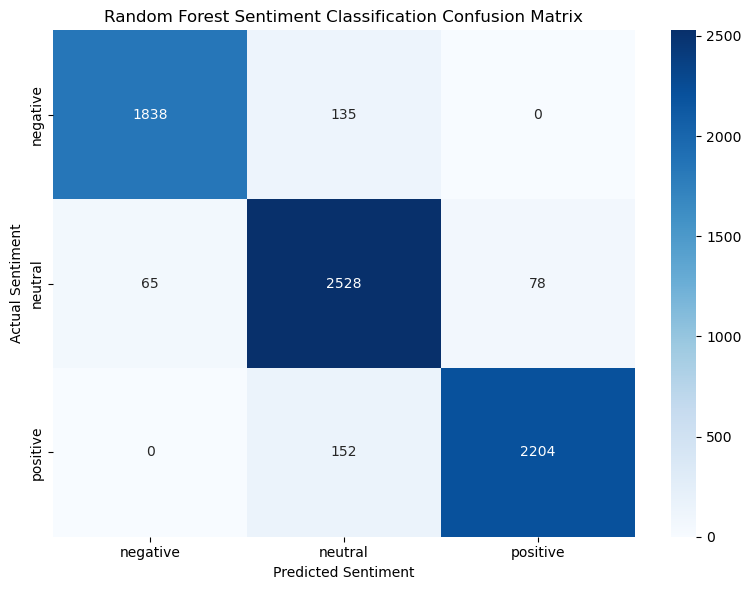

In [16]:
## Visualise the Random Forest confusion matrix
## Let's create a heatmap for easier interpretation
# Import visualisation libraries.
import matplotlib.pyplot as plt
import seaborn as sns

# Define the sentiment categories.
sentiment_classes = ["negative", "neutral", "positive"]

# Generate the confusion matrix.
cm = confusion_matrix(
    y_test,
    y_predict,
    labels=sentiment_classes
)

# Create the heatmap.
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sentiment_classes,
    yticklabels=sentiment_classes
)

# Add chart title and axis labels.
plt.title("Random Forest Sentiment Classification Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.tight_layout()
plt.show()

## Interpreting the results
# Actual sentiment	    Predicted negative	Predicted neutral	Predicted positive
Negative	            1,838 correct	    135 incorrect	    0 incorrect
Neutral	                65 incorrect	     2,528 correct	    78 incorrect
Positive	            0 incorrect	          152 incorrect	    2,204 correct

In [ ]:
# Import Logistic Regression for sentiment classification.
# Import Multinomial Naive Bayes for text classification.
# Import Linear Support Vector Machine.
# Import DummyClassifier to establish a simple majority-class baseline.
# Import additional evaluation metrics.ie, fi_ score, acuracy_score etc

In [18]:
# Initialise Logistic Regression.
logistic_model = LogisticRegression(
    max_iter=2000,             # Allow sufficient iterations for convergence.
    class_weight="balanced",   # Adjust weights for sentiment class imbalance.
    random_state=42            # Ensure reproducibility.
)

# Initialise Multinomial Naive Bayes.
naive_bayes_model = MultinomialNB()

# Initialise Linear Support Vector Machine.
svm_model = LinearSVC(
    class_weight="balanced",  # Adjust weights for class imbalance.
    random_state=42
)

# Initialise a majority-class baseline.
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

print("All additional baseline models have been initialised.")

All additional baseline models have been initialised.


In [19]:
# Train Logistic Regression using the TF-IDF training features.
logistic_model.fit(X_train_tfidf, y_train)

# Predict sentiment categories for the test reviews.
logistic_predict = logistic_model.predict(X_test_tfidf)

# Display the classification report.
print("========== LOGISTIC REGRESSION BASELINE ==========")

print(
    classification_report(
        y_test,
        logistic_predict
    )
)

========== LOGISTIC REGRESSION BASELINE ==========
              precision    recall  f1-score   support

    negative       0.97      0.93      0.95      1973
     neutral       0.89      0.95      0.92      2671
    positive       0.97      0.93      0.95      2356

    accuracy                           0.94      7000
   macro avg       0.94      0.94      0.94      7000
weighted avg       0.94      0.94      0.94      7000



In [20]:
# Train Multinomial Naive Bayes using the TF-IDF training features.
naive_bayes_model.fit(X_train_tfidf, y_train)

# Predict sentiment categories for the test reviews.
naive_bayes_predict = naive_bayes_model.predict(X_test_tfidf)

# Display the classification report.
print("========== MULTINOMIAL NAIVE BAYES BASELINE ==========")

print(
    classification_report(
        y_test,
        naive_bayes_predict
    )
)

========== MULTINOMIAL NAIVE BAYES BASELINE ==========
              precision    recall  f1-score   support

    negative       0.97      0.91      0.94      1973
     neutral       0.87      0.95      0.91      2671
    positive       0.97      0.92      0.94      2356

    accuracy                           0.93      7000
   macro avg       0.94      0.93      0.93      7000
weighted avg       0.93      0.93      0.93      7000



In [21]:
# Train Linear SVM using the TF-IDF training features.
svm_model.fit(X_train_tfidf, y_train)

# Predict sentiment categories for the test reviews.
svm_predict = svm_model.predict(X_test_tfidf)

# Display the classification report.
print("========== SUPPORT VECTOR MACHINE BASELINE ==========")

print(
    classification_report(
        y_test,
        svm_predict
    )
)

========== SUPPORT VECTOR MACHINE BASELINE ==========
              precision    recall  f1-score   support

    negative       0.97      0.93      0.95      1973
     neutral       0.89      0.95      0.92      2671
    positive       0.97      0.93      0.95      2356

    accuracy                           0.94      7000
   macro avg       0.94      0.94      0.94      7000
weighted avg       0.94      0.94      0.94      7000



In [22]:
# Train the majority-class baseline using the training data.
dummy_model.fit(X_train_tfidf, y_train)

# Generate predictions for the test dataset.
dummy_predict = dummy_model.predict(X_test_tfidf)

# Display the classification report.
print("========== MAJORITY CLASS BASELINE ==========")

print(
    classification_report(
        y_test,
        dummy_predict
    )
)

========== MAJORITY CLASS BASELINE ==========
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00      1973
     neutral       0.38      1.00      0.55      2671
    positive       0.00      0.00      0.00      2356

    accuracy                           0.38      7000
   macro avg       0.13      0.33      0.18      7000
weighted avg       0.15      0.38      0.21      7000



c:\Users\telvi\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\telvi\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\telvi\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [23]:
## Compare all baseline models
# This is one of the most important sections of the project. We will evaluate 
# all five models using the same metrics and test dataset.

# Store the predictions from all five baseline models.
model_predictions = {
    "Random Forest": y_predict,
    "Logistic Regression": logistic_predict,
    "Naive Bayes": naive_bayes_predict,
    "Linear SVM": svm_predict,
    "Majority Class": dummy_predict
}

# Create an empty list to store the evaluation results.
model_results = []

# Evaluate each model using consistent performance metrics.
for model_name, predictions in model_predictions.items():

    # Calculate accuracy.
    accuracy = accuracy_score(y_test, predictions)

    # Calculate macro precision.
    macro_precision = precision_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    # Calculate macro recall.
    macro_recall = recall_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    # Calculate macro F1-score.
    macro_f1 = f1_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    # Calculate weighted F1-score.
    weighted_f1 = f1_score(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    )

    # Append the results for the current model.
    model_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro Precision": macro_precision,
        "Macro Recall": macro_recall,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1
    })

# Convert the results into a DataFrame.
results_df = pd.DataFrame(model_results)

# Sort the models according to their macro F1-score.
results_df = results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

# Display the comparative evaluation table.
print("========== BASELINE MODEL COMPARISON ==========")

display(results_df.round(4))

========== BASELINE MODEL COMPARISON ==========


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Random Forest,0.9386,0.9432,0.9378,0.9401,0.9389
1,Logistic Regression,0.9384,0.9438,0.9375,0.9401,0.9388
2,Linear SVM,0.9379,0.9435,0.9367,0.9395,0.9382
3,Naive Bayes,0.9293,0.9370,0.9274,0.9312,0.9298
4,Majority Class,0.3816,0.1272,0.3333,0.1841,0.2108


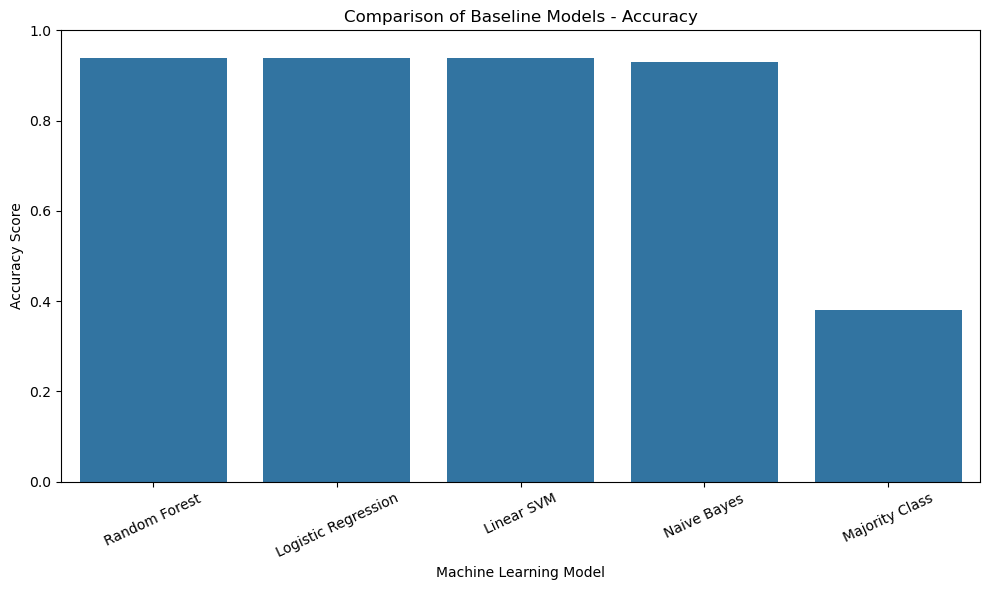

In [24]:
# Visualise comparative model performance
# We will use two separate charts to compare accuracy and macro F1-score.
# Plot the accuracy scores for all baseline models.
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Comparison of Baseline Models - Accuracy")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy Score")
plt.xticks(rotation=25)
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

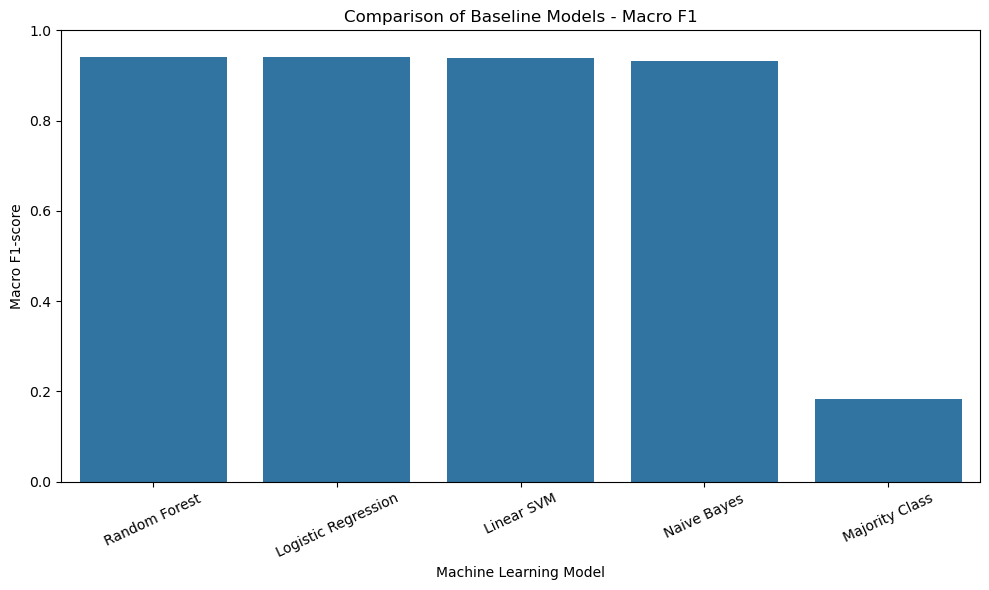

In [25]:
# Plot macro F1-scores for all baseline models.
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Macro F1"
)

plt.title("Comparison of Baseline Models - Macro F1")
plt.xlabel("Machine Learning Model")
plt.ylabel("Macro F1-score")
plt.xticks(rotation=25)
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

In [ ]:
# Identify the model with the highest macro F1-score.
best_model_row = results_df.loc[
    results_df["Macro F1"].idxmax()
]

# Extract the best model name and its performance.
best_model_name = best_model_row["Model"]
best_model_score = best_model_row["Macro F1"]

# Display the best-performing model.
print("========== BEST BASELINE MODEL ==========")

print(f"Best Model: {best_model_name}")
print(f"Macro F1-score: {best_model_score:.4f}")
print(f"Accuracy: {best_model_row['Accuracy']:.4f}")
print(f"Weighted F1: {best_model_row['Weighted F1']:.4f}")

========== BEST BASELINE MODEL ==========
Best Model: Random Forest
Macro F1-score: 0.9401
Accuracy: 0.9386
Weighted F1: 0.9389


## Investigate misclassified reviews
This section helps us understand why certain reviews were incorrectly classified.

For example, a guest might write:
- "The room was excellent, but the staff were disappointing."
- "The location was good, although the food was poor."
Such reviews contain mixed sentiment, making classification more challenging.

In [27]:
# Create a DataFrame containing actual and predicted sentiment labels.
error_analysis = pd.DataFrame({
    "Actual Sentiment": y_test.values,
    "Predicted Sentiment": y_predict,
    "Review Text": X_test.values
})

# Identify incorrectly classified reviews.
misclassified_reviews = error_analysis[
    error_analysis["Actual Sentiment"] !=
    error_analysis["Predicted Sentiment"]
].copy()

# Display the total number of incorrect predictions.
print("Total test reviews:", len(error_analysis))

print(
    "Misclassified reviews:",
    len(misclassified_reviews)
)

# Calculate the misclassification percentage.
error_percentage = (
    len(misclassified_reviews) /
    len(error_analysis)
) * 100

print(f"Misclassification rate: {error_percentage:.2f}%")

# Display the first 20 incorrectly classified reviews.
display(misclassified_reviews.head(20))

Total test reviews: 7000
Misclassified reviews: 430
Misclassification rate: 6.14%


,Actual Sentiment,Predicted Sentiment,Review Text
18,positive,neutral,i d describe the receptionist as acceptable no...
28,negative,neutral,the surrounding area was not the most convenie...
38,neutral,positive,honestly the overall price was very reasonably...
55,negative,neutral,nothing about our visit to manchester stood ou...
67,negative,neutral,the buffet was standard hotel fare nothing mor...
87,negative,neutral,overall the lounge was basic but functional ab...
102,positive,neutral,the cost of the stay was in line with similar ...
144,neutral,positive,i was genuinely impressed that the check in pr...
147,neutral,negative,we had high hopes for this hotel in birmingham...
159,positive,neutral,overall the buffet was standard hotel fare abo...


## Investigate potential duplicate-review leakage
Because we are using a random train/test split, identical reviews could appear in both datasets. This may inflate model performance.

In [28]:
# Identify unique review texts in the training dataset.
train_reviews = set(X_train.str.strip().str.lower())

# Identify unique review texts in the testing dataset.
test_reviews = set(X_test.str.strip().str.lower())

# Find identical reviews appearing in both datasets.
overlapping_reviews = train_reviews.intersection(test_reviews)

# Calculate the number of test records whose text appears in training.
test_overlap_count = (
    X_test.str.strip().str.lower().isin(train_reviews).sum()
)

# Display the overlap results.
print("Unique overlapping review texts:", len(overlapping_reviews))

print(
    "Test records with text also found in training:",
    test_overlap_count
)

print(
    "Percentage of test records affected:",
    round((test_overlap_count / len(X_test)) * 100, 2),
    "%"
)

Unique overlapping review texts: 140
Test records with text also found in training: 150
Percentage of test records affected: 2.14 %


In [29]:
# Display the distribution of sentiment labels across rating scores.
rating_sentiment = pd.crosstab(
    merged["rating_score"],
    merged["sentiment_label"]
)

# Display the cross-tabulation.
print("========== RATING AND SENTIMENT RELATIONSHIP ==========")

display(rating_sentiment)

# Calculate the percentage distribution of sentiment labels per rating.
rating_sentiment_percentage = pd.crosstab(
    merged["rating_score"],
    merged["sentiment_label"],
    normalize="index"
) * 100

# Display the percentage distribution.
display(rating_sentiment_percentage.round(2))

========== RATING AND SENTIMENT RELATIONSHIP ==========


sentiment_label,negative,neutral,positive
rating_score,,,
1.0,654,15,0
1.1,185,7,0
1.2,227,6,0
1.3,294,10,0
1.4,311,10,0
1.5,443,8,0
1.6,446,10,0
1.7,575,19,0
1.8,629,18,0


sentiment_label,negative,neutral,positive
rating_score,,,
1.0,97.76,2.24,0.00
1.1,96.35,3.65,0.00
1.2,97.42,2.58,0.00
1.3,96.71,3.29,0.00
1.4,96.88,3.12,0.00
1.5,98.23,1.77,0.00
1.6,97.81,2.19,0.00
1.7,96.80,3.20,0.00
1.8,97.22,2.78,0.00


## Save all trained baseline models

In [30]:
# Create a directory for saving all trained models.
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Create a dictionary containing all trained models.
trained_models = {
    "Random Forest": rf_model,
    "Logistic Regression": logistic_model,
    "Naive Bayes": naive_bayes_model,
    "Linear SVM": svm_model,
    "Majority Class": dummy_model
}

# Save each trained model using joblib.
for model_name, model in trained_models.items():

    # Convert the model name into a suitable filename.
    file_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    # Define the model file path.
    model_path = MODEL_DIR / f"{file_name}_sentiment_model.joblib"

    # Save the trained model.
    joblib.dump(model, model_path)

    # Display the saved model location.
    print(f"{model_name} saved successfully to: {model_path}")

# Save the fitted TF-IDF vectorizer.
vectorizer_path = MODEL_DIR / "tfidf_vectorizer.joblib"

joblib.dump(tfidf, vectorizer_path)

print(f"\nTF-IDF vectorizer saved successfully to: {vectorizer_path}")

Random Forest saved successfully to: ..\models\random_forest_sentiment_model.joblib
Logistic Regression saved successfully to: ..\models\logistic_regression_sentiment_model.joblib
Naive Bayes saved successfully to: ..\models\naive_bayes_sentiment_model.joblib
Linear SVM saved successfully to: ..\models\linear_svm_sentiment_model.joblib
Majority Class saved successfully to: ..\models\majority_class_sentiment_model.joblib

TF-IDF vectorizer saved successfully to: ..\models\tfidf_vectorizer.joblib


## # saving the baseline model comparison csv file

In [ ]:
# Define the directory for saving processed datasets.
PROCESSED_DIR = Path("../data/processed")
# Define the CSV output path.
csv_path = PROCESSED_DIR / "baseline_sentiment_model_comparison.csv"

# Save the model comparison results.
results_df.to_csv(csv_path, index=False)

# Confirm successful export.
print(f"Baseline model comparison saved successfully to: {csv_path}")

# Display the saved results.
display(pd.read_csv(csv_path))

Baseline model comparison saved successfully to: ..\data\processed\baseline_sentiment_model_comparison.csv


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Random Forest,0.938571,0.943236,0.937841,0.940143,0.938858
1,Logistic Regression,0.938429,0.943833,0.937455,0.940092,0.938763
2,Linear SVM,0.937857,0.943465,0.936735,0.939508,0.938205
3,Naive Bayes,0.929286,0.937021,0.927449,0.931186,0.929792
4,Majority Class,0.381571,0.127190,0.333333,0.184124,0.210770
